# What was being enforced — arrests by offence, and how cases closed

[`walkthrough.ipynb`](walkthrough.ipynb) asks what happened in five cities and
the nation: homicide per resident, the share of homicides cleared, police
strength, and — in one short example — how often a department arrested anyone
at all. It leaves two questions open by construction, and this notebook is
those two plus the machinery they both stand on.

**Arrests by offence.** The arrest total says how often a department arrested
someone, not what for. The route will answer one offence at a time, out of 47
UCR arrest codes; section 1 takes six of them at the same six scopes, per
100,000 residents, on a trailing year, and asks what a department's mix of
arrests looks like and how it moved.

**How a case was closed.** A clearance is an arrest or an *exceptional*
clearance, and `fbi_offenses` serves only the sum. NIBRS records the split in a
field of its own, Data Element 4, and the FBI publishes the incident files that
carry it. Section 2 reads them for New York and Nashville, 2023–2025, through
[`utils/nibrs.py`](utils/nibrs.py) — no API, no key, six zip files.

**The filing schedule underneath the arrest series.** An arrest series breaks
harder than a homicide series: New York's hole runs twenty and a half years and
Washington's twenty-nine and a half, and the tests that read them need more
than the homicide tests do. Section 3 is the tests, the margin between each
threshold and the data, what each department's schedule actually looks like,
and what a step at a date is worth.

Forty-nine calls in all: the arrest total and six codes at six scopes (42), the
four other drug-possession codes nationally (4), and three offence-route series
(3) for the one comparison that needs them. The filing rule is not defined here
— it lives in [`utils/filing.py`](utils/filing.py), which the walkthrough's
section 2 explains and this notebook's section 3 extends.

The other FBI notebooks are about the plumbing: [`api.ipynb`](api.ipynb) covers
the endpoints and the ways they mislead, [`client.ipynb`](client.ipynb) getting
series out of them, [`mcp.ipynb`](mcp.ipynb) the tools a model sees.

Nothing here argues that anything caused anything. Every number below is
printed by the cell above it.


In [2]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Anchor on this notebook's own directory rather than on the working directory:
# VS Code can root a notebook at the workspace folder instead of at the file,
# and then a relative "../" resolves somewhere else entirely and the imports
# below fail with ModuleNotFoundError.
_here = Path.cwd()
_FBI = _here if (_here / "utils" / "mcp.py").exists() else _here / "notebooks" / "fbi"
for _path in (str(_FBI), str(_FBI.parents[1])):      # notebooks/fbi, then the meida root
    if _path not in sys.path:
        sys.path.insert(0, _path)

import asyncio
import textwrap
from datetime import datetime
from typing import Any

import numpy
from matplotlib import pyplot
# Matplotlib accepts a datetime on an axis and converts it with this same
# function; calling it here keeps the type checker's account of the call
# honest, since the stubs type these parameters as floats.
from matplotlib.dates import date2num
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, StrMethodFormatter
from numpy.typing import NDArray

from lib import config
from utils import nibrs
from utils.filing import (Payload, arrest_unreadable, context, local_median, monthly,
                          stamp_source, surrounding, trailing_sum, unreadable)
from utils.mcp import StaleServerError, call_tool

pyplot.style.use(config.glyfish_style)

#: Six of the walkthrough's eight scopes, with the same colours, so that a
#: line means the same place in both notebooks. The NIBRS dates are the agency
#: registry's -- `get_agencies(state)`, walked in client.ipynb section 1 --
#: rather than anything read off a series.
SCOPES: dict[str, dict[str, Any]] = {
    "national":  {"name": "United States", "short": "US",   "nibrs": None,
                  "colour": "0.45"},
    "NY0303000": {"name": "New York City", "short": "NYC",  "nibrs": "2023-01-01",
                  "colour": "#0067C4"},
    "DCMPD0000": {"name": "Washington",    "short": "DC",   "nibrs": "2021-08-01",
                  "colour": "#FF9500"},
    "CA0194200": {"name": "Los Angeles",   "short": "LA",   "nibrs": "2024-05-01",
                  "colour": "#5600C9"},
    "CA0380100": {"name": "San Francisco", "short": "SF",   "nibrs": None,
                  "colour": "#AC9C00"},
    "TN0190100": {"name": "Nashville",     "short": "Nash", "nibrs": "1999-10-01",
                  "colour": "#AC6500"},
}
CITIES = [scope for scope in SCOPES if scope != "national"]

#: The six arrest codes this notebook reads, with the FBI's name for each, a
#: short label for tables, and the reason it is here. The route serves 47; six
#: is what the call budget allows at six scopes, and these six are chosen to
#: span what an arrest can be about rather than to be the largest six.
CODES: dict[str, dict[str, str]] = {
    "11":  {"name": "Murder and Nonnegligent Homicide", "short": "murder",
            "colour": "#B3000C"},
    "50":  {"name": "Assault - Not Specified", "short": "agg. assault",
            "colour": "#FF9500"},
    "70":  {"name": "Larceny - Theft (Not Specified)", "short": "larceny",
            "colour": "#0067C4"},
    "158": {"name": "Drug Possession - Marijuana", "short": "cannabis poss.",
            "colour": "#00834A"},
    "260": {"name": "Driving Under the Influence", "short": "DUI",
            "colour": "#5600C9"},
    "290": {"name": "Disorderly Conduct", "short": "disorderly",
            "colour": "#AC6500"},
}

START, END = "01-1985", "12-2024"
SRS_END = datetime(2021, 1, 1)      # the day the Summary Reporting System closed


## 1. Six arrest codes, and why these six

An arrest in this API is an occasion, not a person: the programme "counts one
arrest for each separate instance in which a person is arrested, cited, or
summoned for an offense", so that "the UCR arrest figures do not reflect the
number of individuals who have been arrested; rather, the arrest data show the
number of times that persons are arrested"
([Persons Arrested](https://ucr.fbi.gov/crime-in-the-u.s/2019/crime-in-the-u.s.-2019/topic-pages/persons-arrested)).
Each one is filed under a single offence code. Nationally in 2023 — the one
window anyone has checked, in [`client.ipynb`](client.ipynb) — the 47 codes sum
to the all-offence total bar 905 arrests of 7,184,021 filed under "Suspicion",
which has no code. So the codes partition the total, and a code is a share of
something.

Six codes at six scopes is 36 calls; with the total at those six scopes, the
four other drug-possession codes nationally and the three offence-route series
the comparisons need, it comes to 49. That is the budget, and it is what fixes
the number of codes at six rather than at ten. The six are chosen to span what
an arrest can be *about* rather than to be the largest six:

- **11, murder and nonnegligent homicide.** The offence the walkthrough reads
  throughout, and the one offence the 2021 counting change cannot have touched:
  nothing outranks a homicide in the hierarchy the old system applied.
- **50, "Assault - Not Specified".** This is *aggravated* assault — the CDE's
  own 2023 breakdown files its 330,173 national arrests under "Aggravated
  Assault". Simple assault is 55, and is not taken here.
- **70, larceny-theft.** The largest property code, and the one property
  offence a department can decide how hard to pursue.
- **158, possession of marijuana.** One of the five possession codes, 156 to
  160. It is here because its legal status changed inside the window in two of
  these cities, which makes it the code most likely to show a department
  stopping rather than a crime stopping — and the cell after the figure shows
  what taking one code of five costs.
- **260, driving under the influence.** The largest of the six nationally in
  every year the tables below print, and an offence with no clearance series
  anywhere in this API.
- **290, disorderly conduct.** The order-maintenance end of the scale, where
  the count is closest to being a record of what the department chose to do.

Three things the codes do not do. There is **no violent-crime or property-crime
code** — violent crime is 11 + 20 + 23 + 30 + 50, property crime 60 + 70 + 90.
**140, 150 and 170 are the unspecified remainders** of prostitution, drug and
gambling arrests rather than those groups' totals. And **20 and 23 both mean
rape**: 23 is empty nationally in 2023 and 20, the legacy definition, holds
that year's 18,769 arrests, so neither alone is the offence.

The rate here is per 100,000 **residents**, computed from the counts and the
population on the same response. The tool's own `unit='rate'` divides by the
participated population — the people living where agencies reported — which is
a different denominator and, at an agency with no residents of its own, zero.


In [3]:
#: Seconds between requests. The allowance is 1,000 an hour shared across
#: everything using the key, and a burst is answered with "503 upstream connect
#: error" -- which is charged to the allowance as well -- so the calls are
#: spaced rather than fired in a loop.
PACE = 6.0
_spent = 0                      # calls that answered
_refused = 0                    # refusals, which cost the allowance and bought nothing


async def paced(name: str, arguments: dict[str, Any], attempts: int = 5) -> Payload:
    """One tool call, after a pause, repeated if the gateway refuses it.

    The client behind the tool already retries a 503 four times, five, ten and
    twenty seconds apart. In a run of fifty requests that is sometimes not
    enough, and a notebook that gives up half way through has spent its
    requests for nothing, so a refusal waits a minute and tries again.

    Every failure is retried, not only a 503, because the gateway also fails
    with nothing to say: one run of this notebook lost its forty-sixth call to
    "Error executing tool fbi_arrests:" and an empty message, on a request the
    server logged as a 200. A stale server is the exception and is re-raised at
    once -- waiting does not restart anything, and the message says so.
    """
    global _spent, _refused
    for attempt in range(attempts):
        await asyncio.sleep(PACE if attempt == 0 else 60.0)
        try:
            payload = await call_tool(name, arguments)
        except StaleServerError:
            raise
        except RuntimeError:
            if attempt == attempts - 1:
                raise
            _refused += 1
            continue
        _spent += 1
        return payload
    raise RuntimeError("unreachable")


# The total and the six codes, at all six scopes: the total because a code is
# only readable as a share of something, and because the filing schedule is
# visible in it and not in a rare code.
arrests: dict[tuple[str, str], Payload] = {}
for code in ("all", *CODES):
    for scope in SCOPES:
        arrests[code, scope] = await paced("fbi_arrests", {
            "scope": scope, "offense": code, "unit": "count", "start": START, "end": END})

# The rest of drug possession, nationally only. 158 is one of five possession
# codes and there is no budget for the other four at six scopes; nationally
# they say how much of possession one code is.
possession: dict[str, Payload] = {}
for code in ("156", "157", "159", "160"):
    possession[code] = await paced("fbi_arrests", {
        "scope": "national", "offense": code, "unit": "count", "start": START, "end": END})

# The two comparisons that need the other route: homicides and their
# clearances nationally, against murder arrests; and New York's homicides,
# against the homicide incidents the NIBRS files carry for the same months.
homicide: dict[tuple[str, str], Payload] = {}
for measure, scope in (("offenses", "national"), ("clearances", "national"),
                       ("offenses", "NY0303000")):
    homicide[measure, scope] = await paced("fbi_offenses", {
        "offense": "homicide", "scope": scope, "measure": measure, "unit": "count",
        "start": START, "end": END})


def header(width: int = 10) -> str:
    """The six scopes as column headings."""
    return "".join(f"{SCOPES[scope]['short']:>{width}}" for scope in SCOPES)


print(f"{_spent} requests, {PACE:.0f}s apart"
      + (f"; {_refused} refused and repeated a minute later" if _refused else "")
      + "\n")
print("Months of the 480 that carry a filing")
print(f"{'code':5} {'offence':16}" + header())
for code in ("all", *CODES):
    label = "all offences" if code == "all" else CODES[code]["short"]
    filings = [sum(1 for observation in arrests[code, scope]["observations"]
                   if observation["value"]) for scope in SCOPES]
    print(f"{code:5} {label:16}" + "".join(f"{count:10d}" for count in filings))

payload = arrests["all", "national"]
print(f"\nvintage {payload['max_data_date']}, refreshed {payload['last_refresh_date']}; "
      f"each response carries {len(payload['observations'])} monthly periods")
print(f"the offence route, for comparison: "
      f"{homicide['offenses', 'national']['geography']} and "
      f"{homicide['offenses', 'NY0303000']['geography']}, "
      f"{len(homicide['offenses', 'national']['observations'])} periods each")


49 requests, 6s apart

Months of the 480 that carry a filing
code  offence                 US       NYC        DC        LA        SF      Nash
all   all offences           480       231       129       466       456       402
11    murder                 480       223       129       466       414       399
50    agg. assault           480       223       129       466       456       402
70    larceny                480       223       129       466       456       402
158   cannabis poss.         480       222       118       451       388       320
260   DUI                    480       226        71       466       456       402
290   disorderly             480       223       128       463       424       402

vintage 09/2026, refreshed 09/15/2026; each response carries 480 monthly periods
the offence route, for comparison: United States and New York City Police Department, 480 periods each


Every national series is complete: 480 months of 480 for the total and for each
of the six codes. Nothing else is.

New York files 231 months of the total and 222 to 226 of each code; Washington
129 of the total, and only **71 of DUI** — a department can file arrests in a
month and file none under a given code, and the two are the same shape in the
payload. Los Angeles is 466 and San Francisco 456, both stopping short at the
end: San Francisco's last arrest filing is December 2023, and the response says
so in a notice rather than in the data. Nashville begins in July 1991, six and
a half years into the window, and its cannabis-possession series begins in 1992
and then stops for six years.

So a code is not a thinner version of the total. It has its own schedule, and
at agency scope it can be missing where the total is present.


In [4]:
def spelling(payload: Payload) -> tuple[int, int]:
    """How many of a response's months are a filed 0, and how many are null."""
    values = [observation["value"] for observation in payload["observations"]]
    return sum(1 for value in values if value == 0), sum(1 for value in values if value is None)


print("A blank month, as each response spells it:  zeros kept as filings / nulls")
print(f"{'code':5} {'offence':16}" + header(12))
for code in ("all", *CODES):
    label = "all offences" if code == "all" else CODES[code]["short"]
    print(f"{code:5} {label:16}" + "".join(
        "{:>12}".format("%d / %d" % spelling(arrests[code, scope])) for scope in SCOPES))


def block(payload: Payload, field: str) -> dict[str, float | None]:
    """One context block as ``{period: value}``, empty where the response has none."""
    return {observation["period"]: observation["value"]
            for observation in (payload.get(field) or {}).get("observations", [])}


CONTEXT = ("population", "participated_population", "coverage")

# Whether a code's response carries its own context or the scope's. If the
# arrest total, every code and the offence route agree in all 480 months, then
# a coverage figure compared across routes is the same number twice.
print("\nThe context blocks, across routes at one scope")
for scope in SCOPES:
    routes = [arrests[code, scope] for code in ("all", *CODES)]
    if (("offenses", scope)) in homicide:
        routes.append(homicide["offenses", scope])
    agree = {field: all(block(payload, field) == block(routes[0], field) for payload in routes)
             for field in CONTEXT}
    months = len(block(routes[0], "coverage"))
    differ = [field for field in CONTEXT if not agree[field]]
    print(f"  {SCOPES[scope]['name']:16} {len(routes)} responses; population, participated "
          f"population and coverage\n{'':18} identical in all {months} months: "
          + (f"no, {differ} differ" if differ else "yes"))

national = arrests["all", "national"]
offence_route = homicide["offenses", "national"]
print(f"\ncoverage on the arrest total {national['coverage_mean_percent']:.2f}% mean, "
      f"{national['coverage_min_percent']:.2f}% at {national['coverage_min_period']}; "
      f"on the offence route {offence_route['coverage_mean_percent']:.2f}% and "
      f"{offence_route['coverage_min_percent']:.2f}% at "
      f"{offence_route['coverage_min_period']}")

# What the responses themselves say about their blanks. The boilerplate every
# arrest response opens with is left out; these are the notices that name
# months.
BLANKS = ("record no filing", "participated population", "past the last filing")
print("\nWhat the responses say about their own blanks:")
seen: set[str] = set()
for code, scope in (("all", "NY0303000"), ("all", "DCMPD0000"), ("11", "CA0380100"),
                    ("158", "CA0380100"), ("158", "TN0190100")):
    for notice in arrests[code, scope]["notices"]:
        if not any(phrase in notice for phrase in BLANKS) or notice[:50] in seen:
            continue
        seen.add(notice[:50])
        print(f"  {code} at {SCOPES[scope]['name']}:")
        print(textwrap.fill(notice, 92, initial_indent="    ", subsequent_indent="    "))


A blank month, as each response spells it:  zeros kept as filings / nulls
code  offence                   US         NYC          DC          LA          SF        Nash
all   all offences           0 / 0     2 / 247    44 / 307      0 / 14      0 / 24      0 / 78
11    murder                 0 / 0     0 / 257    44 / 307      0 / 14     42 / 24      3 / 78
50    agg. assault           0 / 0     0 / 257    44 / 307      0 / 14      0 / 24      0 / 78
70    larceny                0 / 0     0 / 257    44 / 307      0 / 14      0 / 24      0 / 78
158   cannabis poss.         0 / 0     0 / 258    55 / 307      2 / 27     57 / 35     4 / 156
260   DUI                    0 / 0     0 / 254    44 / 365      0 / 14      0 / 24      0 / 78
290   disorderly             0 / 0     0 / 257    44 / 308      1 / 16     32 / 24      0 / 78

The context blocks, across routes at one scope
  United States    8 responses; population, participated population and coverage
                   identical in all 4

Three things in that output, and the third corrects the walkthrough.

**The two spellings of a blank are split by route and by scope.** Nationally
nothing is null: the mapper reads a per-offence null as 0 where the scope's own
participated population is above zero that month, so a national code series
comes back 480 of 480. At agency scope the zeros survive as filings —
San Francisco files a **0 for murder arrests in 42 months**, for cannabis
possession in 57 and for disorderly conduct in 32; Nashville files 3 zero
months of murder arrests and 4 of cannabis possession, Los Angeles 2 of
cannabis possession — while the runs the tool judged to be non-reporting come
back null instead. Washington's 44 are the same spelling and a different fact:
the blank months of four annual returns, 1992 to 1995, which the tool reads as a
filing schedule and hands back as the CDE sent them, so that a caller summing
one of those years gets the year the department filed. The all-offence series
carries few filed zeros otherwise — New York's two months of 2022 are the only
ones here — because a department that files anything files some arrests. A rare code is where the two spellings
meet, and nothing in the payload says which of them a given zero is.

**The notices name the spans and are worth reading before the series.** New
York's notice names 247 months, and the response also carries two filed zeros
in 2022, so 249 of its 480 months are blank one way or the other. Washington's
names 307 and a second notice names the four annual returns its 44 kept zeros
belong to, 351 months between them, San Francisco's twelve months with no
participated population and twelve more past its last filing, Nashville's 156
months of cannabis possession in 1985–1991 and 1994–1999. The notices are the
tool's own non-reporting rule, applied to the counts; section 3 is this
notebook's, applied on top.

**The routes carry the same context, so comparing their coverage proves
nothing.** At every scope, all seven or eight responses — the arrest total,
each code, and the offence route where it was fetched — carry *identical*
population, participated-population and coverage blocks in all 480 months. The
national arrest total and the national homicide series both report 93.68% mean
coverage and both bottom out at 74.12% in February 2021 because they are the
same series of numbers, attached twice. It is tempting to read that agreement
as a check — the two routes report the same coverage, so they must rest on the
same reporting base — and it is no check at all: it is true by construction,
and would be just as true if the two routes counted different agencies
entirely. It also means the coverage figure on an arrest response cannot show
an arrest-specific hole: at agency scope it is the state's figure, as the
notices say.

One consequence for arithmetic. Rescaling a national rate by dividing it over
the reporting population — the walkthrough's section 2 does this, and it is the
right correction to reach for — assumes that what is being counted is
distributed the same way inside and outside the reporting share. That is an
assumption and not a fact, here as there, and it is a larger assumption for
arrests than for homicide: the agencies that stopped reporting in 2021 were
disproportionately the ones that had not converted, and nothing says their
arrest mix matched the ones left behind.


In [5]:
class Arrests:
    """One scope's arrests for one code, cleaned of its filing schedule.

    The rule is ``utils/filing``'s, and which of its two forms applies depends
    on the size of the counts. The all-offence total is counted in thousands a
    month and gets :func:`arrest_unreadable`: the three tests plus a token read
    as a blank, a part-filing line at a third, and a lump measured anywhere.
    A single code is counted in ones and tens at agency scope, where those
    three additions do more harm than good -- section 3 shows the months they
    take -- so a code gets the homicide rule, :func:`unreadable`, and its
    floors.
    """

    def __init__(self, code: str, scope: str, payload: Payload) -> None:
        self.code, self.scope, self.meta = code, scope, SCOPES[scope]
        self.dates, self.filed = monthly(payload)
        self.population = context(payload, "population", self.dates)
        self.coverage = context(payload, "coverage", self.dates)
        self.gaps = (arrest_unreadable if code == "all" else unreadable)(self.filed)
        self.counts = numpy.where(self.gaps, numpy.nan, self.filed)
        # A month is lost either way: the tool returned null, or the rule
        # cannot read the number it returned.
        self.blank = ~numpy.isfinite(self.counts)
        self.arrests = trailing_sum(self.counts)
        self.rate = 1e5 * self.arrests / self.population

    def at(self, values: NDArray[numpy.float64], period: str) -> float:
        """One month's value of a derived series, by 'MM-YYYY'."""
        month, year = (int(part) for part in period.split("-"))
        index = numpy.flatnonzero([date.year == year and date.month == month
                                   for date in self.dates])
        return float(values[index[0]]) if len(index) else float("nan")

    def holes(self) -> list[str]:
        """The stretches with no readable month, as 'YYYY-MM' or 'YYYY-MM..YYYY-MM'."""
        spans, start = [], None
        for i, (date, gap) in enumerate(zip(self.dates, self.blank)):
            if gap and start is None:
                start = date
            elif not gap and start is not None:
                spans.append(f"{start:%Y-%m}" if start == self.dates[i - 1]
                             else f"{start:%Y-%m}..{self.dates[i - 1]:%Y-%m}")
                start = None
        if start is not None:
            spans.append(f"{start:%Y-%m}..{self.dates[-1]:%Y-%m}")
        return spans


read = {(code, scope): Arrests(code, scope, arrests[code, scope])
        for code in ("all", *CODES) for scope in SCOPES}

print("Readable twelve-month windows of the 469 a forty-year monthly series can hold")
print(f"{'code':5} {'offence':16}" + header())
for code in ("all", *CODES):
    label = "all offences" if code == "all" else CODES[code]["short"]
    print(f"{code:5} {label:16}" + "".join(
        f"{int(numpy.isfinite(read[code, scope].rate).sum()):10d}" for scope in SCOPES))

# Two ways a month is lost, kept apart: the tool returned it as null, or the
# tool returned a number and the rule cannot read it as a month.
print(f"\n{'code':5} {'scope':14} {'null':>5} {'rule':>5} {'first':>8} {'last':>8}"
      f"  the unreadable stretches")
for code in ("all", *CODES):
    for scope in SCOPES:
        record = read[code, scope]
        drawn = numpy.flatnonzero(numpy.isfinite(record.rate))
        taken = int((record.gaps & numpy.isfinite(record.filed)).sum())
        spans = record.holes()
        shown = spans if len(spans) <= 3 else spans[:2] + [f"… {len(spans) - 2} more"]
        print(f"{code:5} {SCOPES[scope]['name']:14} "
              f"{int(numpy.isnan(record.filed).sum()):5d} {taken:5d} "
              f"{f'{record.dates[drawn[0]]:%Y-%m}' if len(drawn) else '—':>8} "
              f"{f'{record.dates[drawn[-1]]:%Y-%m}' if len(drawn) else '—':>8}  "
              f"{', '.join(shown) if spans else 'nothing'}")


Readable twelve-month windows of the 469 a forty-year monthly series can hold
code  offence                 US       NYC        DC        LA        SF      Nash
all   all offences           469       188        80       434       434       391
11    murder                 469       188       103       434       434       391
50    agg. assault           469       188       103       434       434       391
70    larceny                469       188        80       434       434       391
158   cannabis poss.         469       176        80       394       379       290
260   DUI                    469       188        43       434       434       391
290   disorderly             469       188        80       422       434       391

code  scope           null  rule    first     last  the unreadable stretches
all   United States      0     0  1985-12  2024-12  nothing
all   New York City    247    11  1985-12  2024-12  1993-01..1993-08, 1993-10..1993-12, 2002-06..2022-12
all   Washingto

**Which rule, and why two.** The all-offence total gets the three arrest
additions — a token read as a blank, a part-filing line at a third rather than
a tenth, a lump measured anywhere — because it is counted in thousands a month.
A single code does not: at agency scope its counts are ones and tens, and at
those sizes a busy month *is* three times the level around it. Section 3 prints
the months the additions would take from single codes if they were applied, and
they are ordinary months. So a code gets the homicide rule and its floors.

**The rule is not the main loss of months; the tool's nulls are.** Reading down
the second table, the `null` column is the tool's non-reporting rule and the
`rule` column is what this notebook takes on top of it — 11 months from New
York's total, 2 from Los Angeles', 0 or 1 from most code series, and 60 from
Washington's total. Washington is the exception and it is the schedule again:
the tool hands back the blank months of its annual returns as filings, and this
notebook's own rule, which knows nothing of schedules, reads 44 of them as the
gap they sit in. Either reading loses those months for a trailing year; what the
tool's schedule buys is a caller who sums the year rather than a chart.

**A rare code at agency scope is the hard case, in both directions.** Cannabis
possession is the example. The tool nulls Nashville's whole of 1994–1999, 72
months in which the department filed arrests every month and none of them under
158. San Francisco's series is left with 35 nulls and 15 months this notebook
takes as well, out of a series whose monthly filings run in ones by 2018. Both
readings are defensible and neither can be checked: a code with no arrests in
it looks exactly like a code nobody filed, and the run test's fall-back level
is the *series' own* median filing — 38.5 a month for San Francisco, a level
that belongs to the 1990s — so a genuinely empty year in 2020 is measured
against a level two decades out of date and read as a gap. That is the shape to
distrust in the figure below: a code line that ends or breaks at an agency is
at least as likely to be a filing fact as an enforcement one.


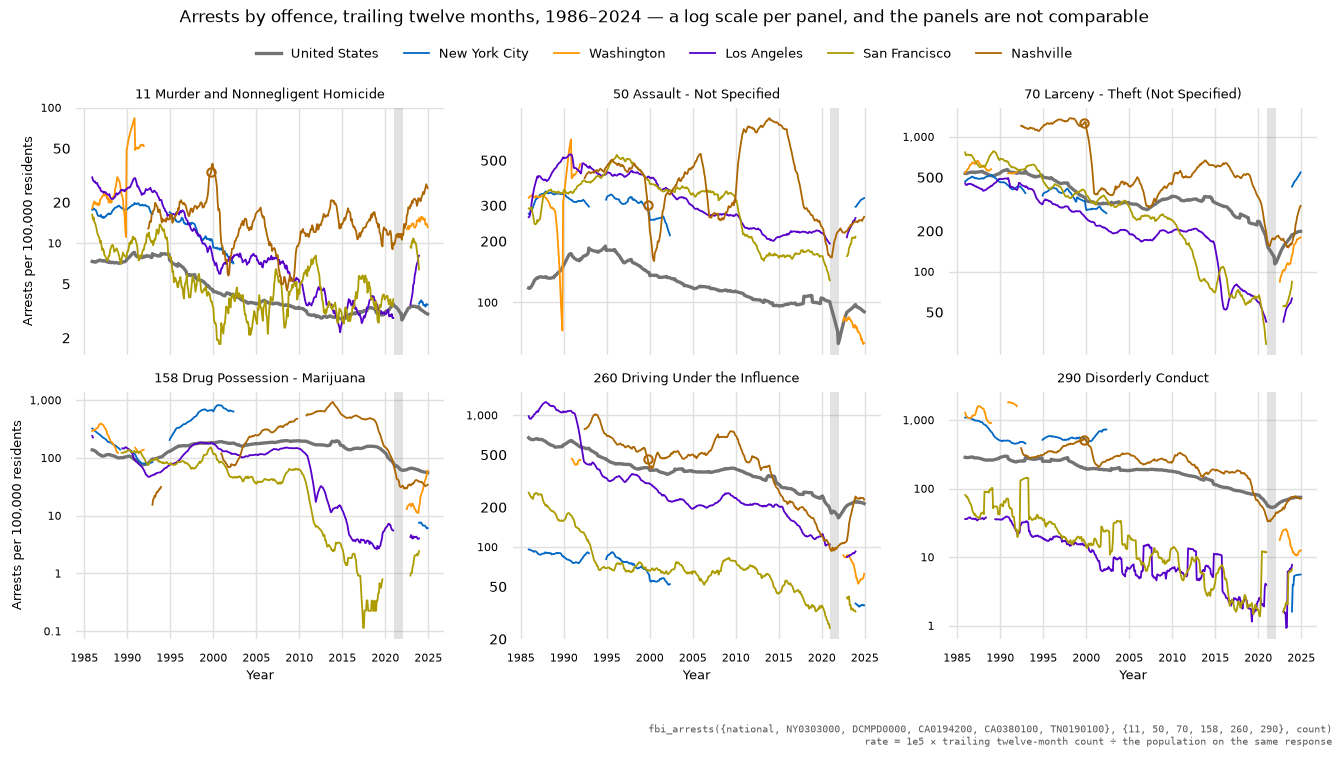

In [6]:
figure, axes = pyplot.subplots(2, 3, figsize=(13.5, 7.5), sharex=True)
for code, axis in zip(CODES, axes.flat):
    axis.set_axisbelow(True)
    axis.axvspan(date2num(SRS_END), date2num(datetime(2022, 1, 1)),
             color="0.55", alpha=0.25, lw=0)
    for scope in SCOPES:
        record = read[code, scope]
        axis.plot(record.dates, record.rate, color=record.meta["colour"],
                  lw=2.4 if scope == "national" else 1.3, label=record.meta["name"],
                  zorder=2 if scope == "national" else 3)
        # A ring where the department's conversion month has a readable year
        # behind it. Most do not: the filing schedule, seen from the inside.
        if record.meta["nibrs"]:
            converted = datetime.strptime(record.meta["nibrs"], "%Y-%m-%d")
            value = record.at(record.rate, f"{converted.month:02d}-{converted.year}")
            if numpy.isfinite(value):
                axis.plot([converted], [value], marker="o", markersize=6, mfc="none",
                          mew=1.5, color=record.meta["colour"], zorder=4)
    axis.set_yscale("log")
    # A panel spanning less than a decade has one labelled tick unless the
    # minor ticks carry labels too, and matplotlib spells those in scientific
    # notation; a panel spanning three gets an unreadable ladder of them. So
    # the labels thin out as the panel's range widens.
    # A rate below one a year still has to read as a number: San Francisco's
    # cannabis-possession line reaches 0.3 per 100,000.
    ticks = FuncFormatter(lambda value, _: f"{value:,.0f}" if value >= 1 else f"{value:.2g}")
    axis.yaxis.set_major_formatter(ticks)
    low, high = axis.get_ylim()
    subs = (2, 3, 5) if high / low < 30 else (2, 5) if high / low < 300 else ()
    if subs:
        axis.yaxis.set_minor_locator(LogLocator(base=10, subs=subs, numticks=20))
        axis.yaxis.set_minor_formatter(ticks)
    else:
        axis.yaxis.set_minor_formatter(NullFormatter())
    axis.set_title(f"{code} {CODES[code]['name']}", fontsize=9.5)
    axis.tick_params(labelsize=8)
for axis in axes[:, 0]:
    axis.set_ylabel("Arrests per 100,000 residents", fontsize=9)
for axis in axes[1, :]:
    axis.set_xlabel("Year", fontsize=9)
handles = axes[0, 0].get_lines()[:len(SCOPES)]
figure.suptitle("Arrests by offence, trailing twelve months, 1986–2024 — a log scale per "
                "panel, and the panels are not comparable", fontsize=12, y=0.99)
# The legend under the title rather than at the foot, which the source stamp has.
figure.legend(handles, [str(handle.get_label()) for handle in handles], loc="upper center",
              bbox_to_anchor=(0.5, 0.955), ncols=len(SCOPES), fontsize=9, frameon=False)
figure.tight_layout()
figure.subplots_adjust(top=0.86)
stamp_source("fbi_arrests({national, NY0303000, DCMPD0000, CA0194200, CA0380100, TN0190100}, "
             "{11, 50, 70, 158, 260, 290}, count)",
             "rate = 1e5 × trailing twelve-month count ÷ the population on the same response",
             figure=figure)


Six panels, each on its own log scale, and **the panels are not comparable with
each other** — murder arrests run in single figures per 100,000 and larceny
arrests in hundreds. Within a panel the six lines are comparable, with the
usual caution that a level crossing 2021 crosses a break.

**Every panel falls, and they do not fall together.** The national line is the
thick grey one: murder arrests 8 per 100,000 in 1990 and 3 in 2024, larceny 562
and 199, DUI 642 and 213, disorderly conduct 273 and 74. Cannabis possession is
the exception in shape: 93 per 100,000 in 1990, rising to 191 by 2000 and 192
by 2010, then falling to 55. It is the only one of the six whose national line
is higher in 2010 than in 1990.

**The cities' lines sit above the national one almost everywhere**, which is
what a city arrest rate against a national one looks like: the denominator of
the national rate includes everywhere nobody was arrested.

**Nashville's assault panel is the largest single-city movement here.** Its
highest readable window is 808 arrests per 100,000 in the year to December
2013, against a national high of 189 in 1994 and a Nashville figure of 264 in
2024. Its cannabis line peaks at 927 in the same year. Section 3's steps table
takes the step into that decade apart; nothing in the response says what it is.

**The cannabis panel is what a code drying up looks like.** San Francisco runs
127 per 100,000 in the year to December 1990 and 29 by 2010, then 1.9 in 2015
and 2.4 in 2023; Los Angeles 91, 139 in 2000, 110 in 2010 and 4.4 in 2015.
Their national line falls from 192 in 2010 to 62 in 2023. Neither city's line
proves the department stopped arresting rather than stopped filing that code —
the section below is about exactly that — but a fall of that size has no other
candidate in the figure.

**The rings are the conversion dates**, one per department, drawn where a
readable year sits behind the month. Most panels have one or two of them and
none of them is where a line does anything.


In [7]:
YEARS = (1990, 2000, 2010, 2019, 2024)


def december(code: str, scope: str, year: int) -> float:
    """The trailing-twelve-month rate at a December, NaN where unreadable."""
    return read[code, scope].at(read[code, scope].rate, f"12-{year}")


print("Arrests per 100,000 residents, twelve months to December, United States")
print(f"{'code':5} {'offence':16}" + "".join(f"{year:>10}" for year in YEARS)
      + f"{'share of all, 2024':>20}")
for code in ("all", *CODES):
    label = "all offences" if code == "all" else CODES[code]["short"]
    share = december(code, "national", 2024) / december("all", "national", 2024)
    print(f"{code:5} {label:16}"
          + "".join(f"{december(code, 'national', year):10,.0f}" for year in YEARS)
          + (f"{100 * share:19.1f}%" if code != "all" else f"{'—':>20}"))

print("\nThe same, as a share of the scope's own arrest total in that year (%)")
print(f"{'code':5} {'offence':16}" + "".join(f"{year:>10}" for year in YEARS))
for code in CODES:
    print(f"{code:5} {CODES[code]['short']:16}" + "".join(
        f"{100 * december(code, 'national', year) / december('all', 'national', year):10.1f}"
        for year in YEARS))

print("\nThe six codes at the six scopes, per 100,000 residents, twelve months to "
      "December 2019 and 2024")
print(f"{'scope':14} " + "".join(f"{CODES[code]['short']:>15}" for code in CODES))
for year in (2019, 2024):
    print(f"  {year}")
    for scope in SCOPES:
        cells = []
        for code in CODES:
            value = december(code, scope, year)
            cells.append(f"{value:15,.0f}" if numpy.isfinite(value) else f"{'—':>15}")
        print(f"{SCOPES[scope]['name']:14} " + "".join(cells))

print("\nThe highest readable twelve-month window of each code, per 100,000 residents")
print(f"{'code':5} {'offence':16}" + "".join(f"{SCOPES[scope]['short']:>13}" for scope in SCOPES))
for code in ("all", *CODES):
    label = "all offences" if code == "all" else CODES[code]["short"]
    cells = []
    for scope in SCOPES:
        record = read[code, scope]
        drawn = numpy.flatnonzero(numpy.isfinite(record.rate))
        peak = drawn[numpy.argmax(record.rate[drawn])] if len(drawn) else None
        cells.append(f"{record.rate[peak]:8,.0f} {record.dates[peak]:%Y}"
                     if peak is not None else f"{'—':>13}")
    print(f"{code:5} {label:16}" + "".join(cells))

# What the six leave out. The codes are not a partition of the total: the FBI
# files each arrest under one of 47, and these six are six of them.
covered = sum(december(code, "national", 2024) for code in CODES)
print(f"\nthe six codes are {100 * covered / december('all', 'national', 2024):.1f}% of the "
      f"national total in the year to December 2024; the other 41 codes are the rest")


Arrests per 100,000 residents, twelve months to December, United States
code  offence               1990      2000      2010      2019      2024  share of all, 2024
all   all offences         5,800     4,910     4,355     3,113     2,070                   —
11    murder                   8         4         3         3         3                0.1%
50    agg. assault           172       135       110       105        90                4.3%
70    larceny                562       325       343       236       199                9.6%
158   cannabis poss.          93       191       192       124        55                2.7%
260   DUI                    642       381       371       241       213               10.3%
290   disorderly             273       196       168        80        74                3.6%

The same, as a share of the scope's own arrest total in that year (%)
code  offence               1990      2000      2010      2019      2024
11    murder                 0.1       0

**The mix moved, and the total moved further.** The national arrest rate fell
from 5,800 per 100,000 in 1990 to 2,070 in 2024, and each of the six codes fell
with it. Shares are the part that is not just the total shrinking: DUI is 11.1%
of all arrests in 1990, 7.7% in 2019 and 10.3% in 2024; larceny 9.7%, 7.6%,
9.6%; aggravated assault 3.0%, 3.4%, 4.3%; disorderly conduct 4.7%, 2.6%, 3.6%;
cannabis possession 1.6% in 1990, 4.4% in 2010, 2.7% in 2024. Murder is 0.1%
throughout, which is the scale at which the offence the walkthrough spends
forty years on appears in an arrest total.

**The six codes are 30.7% of the 2024 national total**, 10,312 murder arrests
among 7,111,076 of every kind. The other 41 codes hold the remaining 69%, among
them 310, "All Other Offenses (Except Traffic)", which is not taken here. So
"what was being enforced" is answered for a third of the enforcement.

**Between cities, the mixes differ more than the totals do.** In the year to
December 2024 New York arrests at 544 per 100,000 for larceny and 36 for DUI;
Nashville at 307 and 228; Washington at 180 and 63. Nashville's murder-arrest
rate, 25 per 100,000, is six times New York's 4 and twice Washington's 13. All
three were filing under NIBRS in that year, so this particular comparison is
not one system against another — but it is still three departments' charging
practice as much as three cities' crime, and nothing here separates those.

**Los Angeles and San Francisco have no 2024 column**, because their arrest
series stop in 2024 and 2023 respectively; their 2019 column is the last one
that crosses no hole. Read down that column instead: Los Angeles 220 per
100,000 for aggravated assault against San Francisco's 169 and Nashville's 237,
and 6 for cannabis possession against Nashville's 155.

One figure in the peaks table deserves its own line, because it is the largest
single-code rate at any of these scopes: **New York's 806 cannabis-possession
arrests per 100,000 residents in the year to December 2000**, about one arrest
for every 124 residents, under a code that by 2023 reads 7.5.


In [8]:
# Drug possession is five codes, 156 to 160, and the by-offence panel takes one
# of them. Nationally the other four are affordable, so the cost of taking one
# is measurable rather than assumed.
POSSESSION = {"156": "unspecified", "157": "opium or cocaine", "158": "marijuana",
              "159": "synthetic narcotics", "160": "other dangerous nonnarcotic"}
group = {code: (arrests["158", "national"] if code == "158" else possession[code])
         for code in POSSESSION}
series = {code: monthly(payload) for code, payload in group.items()}


def calendar_year(code: str, year: int) -> float:
    """One code's national arrests in a calendar year, NaN if a month is missing."""
    dates, values = series[code]
    return float(values[[date.year == year for date in dates]].sum())


print("National drug-possession arrests by code, calendar years")
print(f"{'code':5} {'possession of':28}" + "".join(f"{year:>12}" for year in
                                                   (1990, 2000, 2010, 2019, 2024)))
for code, label in POSSESSION.items():
    print(f"{code:5} {label:28}" + "".join(f"{calendar_year(code, year):12,.0f}"
                                           for year in (1990, 2000, 2010, 2019, 2024)))
print(f"{'':5} {'all five':28}" + "".join(
    f"{sum(calendar_year(code, year) for code in POSSESSION):12,.0f}"
    for year in (1990, 2000, 2010, 2019, 2024)))
shares = [100 * calendar_year("158", year) / sum(calendar_year(code, year)
                                                 for code in POSSESSION)
          for year in (1990, 2000, 2010, 2019, 2024)]
print(f"{'158':5} {'as a share of the five, %':28}"
      + "".join(f"{share:12.1f}" for share in shares))

# The group against the arrest total it sits in, in the same calendar years.
total_dates, total_counts = monthly(arrests["all", "national"])
totals = {year: float(total_counts[[date.year == year for date in total_dates]].sum())
          for year in (2019, 2024)}
five = {year: sum(calendar_year(code, year) for code in POSSESSION) for year in (2019, 2024)}
print(f"\nnational arrests, all offences: {totals[2019]:,.0f} in 2019 and "
      f"{totals[2024]:,.0f} in 2024, {100 * (totals[2024] / totals[2019] - 1):+.0f}%")
print(f"the five possession codes: {five[2019]:,.0f} and {five[2024]:,.0f}, "
      f"{100 * (five[2024] / five[2019] - 1):+.0f}%")

# And what one code looks like where the counts are small: the same code at the
# six scopes, at the Decembers each can be read.
print("\nCannabis possession per 100,000 residents, twelve months to December, where readable")
DECEMBERS = (1990, 2000, 2010, 2015, 2019, 2023)
print(f"{'place':16}" + "".join(f"{year:>9}" for year in DECEMBERS))
for scope in SCOPES:
    cells = []
    for year in DECEMBERS:
        value = read["158", scope].at(read["158", scope].rate, f"12-{year}")
        cells.append(f"{value:9,.1f}" if numpy.isfinite(value) else f"{'—':>9}")
    print(f"{SCOPES[scope]['name']:16}" + "".join(cells))


National drug-possession arrests by code, calendar years
code  possession of                       1990        2000        2010        2019        2024
156   unspecified                      646,435   1,006,410   1,054,748     606,274      26,013
157   opium or cocaine                 315,369     293,673     209,141     239,361     123,919
158   marijuana                        231,398     537,769     591,355     410,079     190,182
159   synthetic narcotics               14,472      26,087      53,185      56,421      42,849
160   other dangerous nonnarcotic       85,182     148,747     201,068     371,838     315,306
      all five                       1,292,856   2,012,686   2,109,497   1,683,973     698,269
158   as a share of the five, %           17.9        26.7        28.0        24.4        27.2

national arrests, all offences: 10,316,114 in 2019 and 7,111,076 in 2024, -31%
the five possession codes: 1,683,973 and 698,269, -59%

Cannabis possession per 100,000 residents, twel

**One code of five is a moving share of a moving group.** Marijuana possession
is 17.9% of national possession arrests in 1990, 28.0% in 2010 and 27.2% in
2024, so the single code is not a fixed window on the group.

The group's own composition breaks harder than that. Code 156, "Drug
Possession (Unspecified)", falls from 606,274 national arrests in 2019 to
**26,013 in 2024** while the other four hold their order of magnitude. A
summary reporter filing a possession arrest without naming the substance is
what 156 is for, and there are almost none left; the same arrests are now filed
under 157 to 160. So a possession series that crosses 2021 is reading a
reclassification as well as an enforcement change, and 158 crosses it less
badly than 156 does — which is a reason to prefer a named substance to the
unspecified remainder, not a reason to trust the crossing.

All five together fall from 1,683,973 arrests in 2019 to 698,269 in 2024,
−59%, against −31% for arrests of every kind over the same two years. Whether
that is fewer possession arrests, a different set of agencies reporting, or
possession arrests filed under codes outside 156–160, these five series cannot
say.


In [9]:
def calendar_years(dates: NDArray[numpy.object_],
                   values: NDArray[numpy.float64]) -> dict[int, float]:
    """Calendar-year totals of a monthly series, NaN for a year with a month missing."""
    totals: dict[int, float] = {}
    for date, value in zip(dates, values):
        totals[date.year] = totals.get(date.year, 0.0) + float(value)
    return totals


murder_dates, murder_counts = monthly(arrests["11", "national"])
offence_dates, cleared = monthly(homicide["clearances", "national"])
_, recorded = monthly(homicide["offenses", "national"])
by_arrest = calendar_years(murder_dates, murder_counts)
by_clearance = calendar_years(offence_dates, cleared)
by_offence = calendar_years(offence_dates, recorded)

print("The United States, calendar years: murder arrests (fbi_arrests, code 11) beside"
      "\nhomicide clearances and homicides (fbi_offenses)")
print(f"{'year':6}{'arrests':>10}{'clearances':>12}{'homicides':>11}{'arrests ÷ clearances':>23}")
for year in (1990, 2000, 2010, 2019, 2023, 2024):
    print(f"{year:<6}{by_arrest[year]:10,.0f}{by_clearance[year]:12,.0f}{by_offence[year]:11,.0f}"
          f"{by_arrest[year] / by_clearance[year]:23.2f}")
paired = [year for year in by_arrest
          if numpy.isfinite(by_arrest[year]) and numpy.isfinite(by_clearance.get(year, numpy.nan))]
more = [year for year in paired if by_arrest[year] > by_clearance[year]]
print(f"\nmurder arrests outnumber homicide clearances in {len(more)} of {len(paired)} years"
      + (f"; not in {', '.join(str(year) for year in paired if year not in more)}"
         if 0 < len(more) < len(paired) else ""))
print(f"the ratio is {by_arrest[1990] / by_clearance[1990]:.2f} arrests per clearance in 1990 "
      f"and {by_arrest[2024] / by_clearance[2024]:.2f} in 2024")


The United States, calendar years: murder arrests (fbi_arrests, code 11) beside
homicide clearances and homicides (fbi_offenses)
year     arrests  clearances  homicides   arrests ÷ clearances
1990      20,470      14,963     22,770                   1.37
2000      11,856       8,598     14,728                   1.38
2010       9,368       8,419     14,576                   1.11
2019      10,180       9,226     16,711                   1.10
2023      11,451      11,347     19,790                   1.01
2024      10,312      10,411     17,261                   0.99

murder arrests outnumber homicide clearances in 39 of 40 years; not in 2024
the ratio is 1.37 arrests per clearance in 1990 and 0.99 in 2024


**Narrowed to one offence, arrests still outnumber clearances.** Nationally,
murder arrests exceed homicide clearances in **39 of the 40 years** — 20,470
against 14,963 in 1990, 10,180 against 9,226 in 2019 — and 2024 is the one year
they do not, 10,312 against 10,411. Were an arrest the arrest half of a
clearance, the arrest count could never be the larger. It is what the FBI's
"the arrest of one person may clear several crimes, and the arrest of many
persons may clear only one offense"
([Clearances](https://ucr.fbi.gov/crime-in-the-u.s/2019/crime-in-the-u.s.-2019/topic-pages/clearances))
allows for, though neither response says that is what happened.

The ratio falls from 1.37 arrests per clearance in 1990 to 0.99 in 2024, and
the pair cannot say why: more homicides closed by exceptional means, fewer
people arrested per homicide closed, or a change in how either count is filed
would each lower it. Section 2 can see the first of those three in one city's
incident files, and only there.

What this table is **not** evidence of is that the two routes rest on the same
reporting base. They report the same coverage because they carry the same
coverage block, as the cell above measured: the same numbers, attached twice.


## 2. How a case was closed — clearance reasons, from the incident files

A **clearance** is an offence the department has closed, in one of two ways: an
arrest where the case is referred for prosecution, or an *exceptional*
clearance, where the offender is identified and located but something outside
the department's control prevents the arrest — the suspect is dead, in custody
elsewhere and not extraditable, prosecution is declined, or the victim will not
cooperate. `fbi_offenses` serves one clearance count and never the split. The
Summary Reporting System did not record it: "The UCR Program does not
distinguish between offenses cleared by arrest and those cleared by exceptional
means in collecting or publishing data via the traditional Summary Reporting
System" (Clearances, as above). NIBRS does record it, as
[Data Element 4](https://ucr.fbi.gov/nibrs/nibrs-user-manual), Cleared
Exceptionally, and an agency "cannot clear an incident exceptionally if it was
previously or is concurrently cleared by arrest".

That field is in the incident files the FBI publishes for download, one zip per
state and year, and [`utils/nibrs.py`](utils/nibrs.py) reads it straight from
the zips: no API, no key, and nothing in this section spends a request. Two
agencies, three years each, six files already cached under
`notebooks/fbi/data/nibrs/`.

**What the unit is.** The incident, not the offence and not the victim. NIBRS
clears incidents; an incident carrying several of the eight offences counts
once under each of them, so the offence rows do not add to the number of
incidents. An incident is *cleared by arrest* if it has any arrestee record,
whatever the clearance field says, because the first arrestee segment clears
it; otherwise it takes its A–E code if it has one, and otherwise it is not
cleared.

**Four things to carry through the numbers**, each measured on these six files
and set out in the module's docstring. Each year's file holds arrests only up
to a cutoff early in the following year, so a December incident has had about
two months to be cleared and a January incident about fourteen: compare like
months, or pool whole years. New York's rape counts are unreliable from
September 2024 to July 2025. NIBRS homicide runs below the murder count the CDE
serves for the same agency. And the files carry no zero reports, so a month
nobody filed cannot be told from a quiet one.


In [11]:
NIBRS_YEARS = (2023, 2024, 2025)
NIBRS_SCOPES = {"NY0303000": "NY0303000", "TN0190100": "TN0190100"}

incidents = {ori: nibrs.clearance_by_reason(ori, NIBRS_YEARS) for ori in NIBRS_SCOPES}

print(f"{'agency':16} {'ORI':10} {'listed as':40} {'NIBRS from':11}")
for ori in NIBRS_SCOPES:
    listed = nibrs.agency(ori, NIBRS_YEARS[-1])
    print(f"{SCOPES[ori]['name']:16} {ori:10} {listed.name[:40]:40} "
          f"{listed.nibrs_start_date[:10]:11}")

print(f"\nOffence-incident rows by year — the unit is the incident, counted once under "
      f"each\nof the eight offences it carries")
print(f"{'agency':16}" + "".join(f"{year:>10}" for year in NIBRS_YEARS)
      + f"{'cleared by arrest':>19}{'exceptionally':>15}{'not cleared':>13}")
for ori, cells in incidents.items():
    rows = {year: sum(cell.incidents for cell in cells if cell.year == year)
            for year in NIBRS_YEARS}
    by_reason = {reason: sum(cell.incidents for cell in cells if cell.reason == reason)
                 for reason in nibrs.REASONS}
    exceptional = sum(by_reason[reason] for reason in "ABCDE")
    total = sum(by_reason.values())
    print(f"{SCOPES[ori]['name']:16}" + "".join(f"{rows[year]:10,d}" for year in NIBRS_YEARS)
          + f"{by_reason['arrest']:12,d} {100 * by_reason['arrest'] / total:5.1f}%"
          + f"{exceptional:8,d} {100 * exceptional / total:5.1f}%"
          + f"{by_reason['not_cleared']:12,d}")

print("\nExceptional clearances by year and code, as rows of the eight offences")
print(f"{'agency':16} {'year':6}" + "".join(f"{code:>8}" for code in "ABCDE") + f"{'all':>8}")
for ori, cells in incidents.items():
    for year in NIBRS_YEARS:
        counts = {code: sum(cell.incidents for cell in cells
                            if cell.year == year and cell.reason == code) for code in "ABCDE"}
        print(f"{SCOPES[ori]['name']:16} {year:<6}"
              + "".join(f"{counts[code]:8,d}" for code in "ABCDE")
              + f"{sum(counts.values()):8,d}")


agency           ORI        listed as                                NIBRS from 
New York City    NY0303000  New York                                 2023-01-01 
Nashville        TN0190100  Metropolitan Nashville Police Department 1999-10-01 

Offence-incident rows by year — the unit is the incident, counted once under each
of the eight offences it carries
agency                2023      2024      2025  cleared by arrest  exceptionally  not cleared
New York City      254,493   255,550   252,128     259,363  34.0%      28   0.0%     502,780
Nashville           37,348    38,303    33,292      10,972  10.1%   4,010   3.7%      93,961

Exceptional clearances by year and code, as rows of the eight offences
agency           year         A       B       C       D       E     all
New York City    2023         4       0       0       2       0       6
New York City    2024         9       0       0       1       5      15
New York City    2025         3       0       0       3       1       7
N

**New York City records almost no exceptional clearance at all.** Twenty-eight
offence-incident rows of 762,171 across three years — 6, 15 and 7 — against
259,363 cleared by arrest. Nashville sets an A–E code on 4,010 rows of 108,943,
1,358 and 1,488 and 1,164 by year.

That is a difference in recording practice, not in data quality, and it is the
reason the two cities are on the same page. The A–E bands are invisible in New
York's half of the figure below because they are 0.004% of its rows; they are
visible in Nashville's because they are 3.7%. Nothing here says which
department is right, and nothing in the files says whether New York closes the
cases Nashville closes under code D by some other route or does not close them.

Nashville's codes are not spread evenly either: **D, "victim refused to
cooperate", is 1,140 of its 1,358 exceptional rows in 2023**, 1,197 of 1,488 in
2024 and 937 of 1,164 in 2025, with B, "prosecution declined", next at 134 to
192. C,
"in custody of other jurisdiction", is used zero times by either department in
any of the three years.


In [12]:
pooled = {ori: nibrs.pooled(cells) for ori, cells in incidents.items()}

print("Pooled 2023-2025, % of each offence's incident rows, by how they were cleared")
for ori, shares in pooled.items():
    print(f"\n{SCOPES[ori]['name']} ({ori})")
    print(f"{'offence':22}{'rows':>9}" + "".join(
        f"{reason.replace('not_cleared', 'none'):>9}" for reason in nibrs.REASONS))
    for offense in nibrs.OFFENSES:
        rows = [share for share in shares if share.offense == offense]
        total = sum(share.incidents for share in rows)
        print(f"{offense.replace('_', ' '):22}{total:9,d}"
              + "".join(f"{100 * share.share:9.1f}" for share in rows))

print("\nWhat each code means, as NIBRS_CLEARED_EXCEPT.csv labels it")
for reason in nibrs.REASONS:
    print(f"  {reason:12} {nibrs.REASON_LABELS[reason]}")


Pooled 2023-2025, % of each offence's incident rows, by how they were cleared

New York City (NY0303000)
offence                    rows   arrest        A        B        C        D        E     none
homicide                    950     66.7      0.9      0.0      0.0      0.0      0.0     32.3
rape                      7,436     36.7      0.0      0.0      0.0      0.0      0.0     63.2
robbery                  46,931     51.3      0.0      0.0      0.0      0.0      0.0     48.7
aggravated assault      109,408     69.5      0.0      0.0      0.0      0.0      0.0     30.4
burglary                 40,242     40.9      0.0      0.0      0.0      0.0      0.0     59.1
larceny                 504,185     25.9      0.0      0.0      0.0      0.0      0.0     74.1
motor vehicle theft      50,648     16.6      0.0      0.0      0.0      0.0      0.0     83.4
arson                     2,371     25.4      0.0      0.0      0.0      0.0      0.0     74.6

Nashville (TN0190100)
offence          

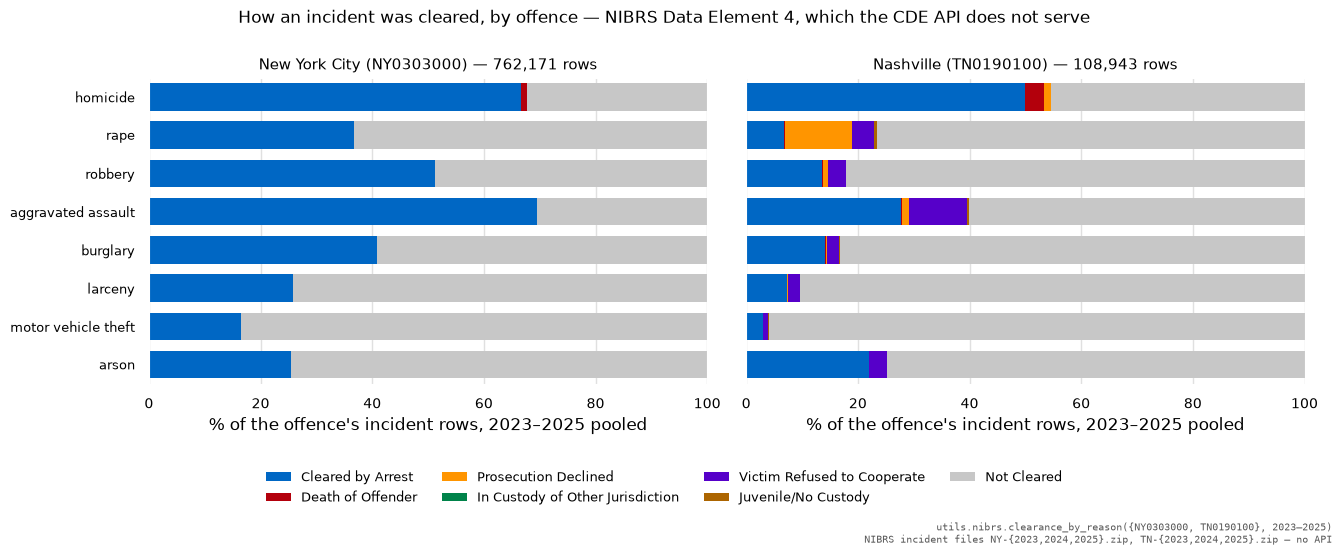

In [20]:
BANDS = {"arrest": "#0067C4", "A": "#B3000C", "B": "#FF9500", "C": "#00834A",
         "D": "#5600C9", "E": "#AC6500", "not_cleared": "0.78"}

figure, axes = pyplot.subplots(1, 2, figsize=(13.5, 5.5), sharex=True, sharey=True)
for axis, (ori, shares) in zip(axes, pooled.items()):
    offenses = [offense for offense in nibrs.OFFENSES]
    positions = numpy.arange(len(offenses))
    left = numpy.zeros(len(offenses))
    for reason in nibrs.REASONS:
        widths = numpy.array([100 * next(share.share for share in shares
                                         if share.offense == offense and share.reason == reason)
                              for offense in offenses])
        axis.barh(positions, widths, left=left, color=BANDS[reason], height=0.72,
                  label=nibrs.REASON_LABELS[reason])
        left += widths
    axis.set_yticks(positions)
    axis.set_yticklabels([offense.replace("_", " ") for offense in offenses], fontsize=9)
    axis.set_ylim(len(offenses) - 0.5, -0.5)          # homicide at the top
    axis.set_xlim(0, 100)
    axis.set_xlabel("% of the offence's incident rows, 2023–2025 pooled")
    rows = sum(share.incidents for share in shares)
    axis.set_title(f"{SCOPES[ori]['name']} ({ori}) — {rows:,} rows", fontsize=11)
    axis.grid(axis="y", visible=False)
handles = [Patch(facecolor=BANDS[reason], label=nibrs.REASON_LABELS[reason])
           for reason in nibrs.REASONS]
figure.legend(handles, [str(handle.get_label()) for handle in handles], loc="lower center",
              bbox_to_anchor=(0.5, 0.06), ncols=4, fontsize=9, frameon=False)
figure.suptitle("How an incident was cleared, by offence — NIBRS Data Element 4, which "
                "the CDE API does not serve", fontsize=12)
figure.tight_layout()
stamp_source("utils.nibrs.clearance_by_reason({NY0303000, TN0190100}, 2023–2025)",
             "NIBRS incident files NY-{2023,2024,2025}.zip, TN-{2023,2024,2025}.zip — no API",
             figure=figure)
figure.subplots_adjust(bottom=0.30)


**By arrest, the two departments are four points apart on homicide and twenty
on everything else.** New York clears 66.7% of its homicide rows by arrest and
Nashville 50.0%; for aggravated assault it is 69.5% against 27.7%, for larceny
25.9% against 7.3%, for motor vehicle theft 16.6% against 2.9%. Across all
eight offences New York is 34.0% by arrest and Nashville 10.1%.

**Where Nashville uses an exceptional clearance, it uses it heavily and for
particular offences.** Rape: 6.7% cleared by arrest, and **11.9% by code B,
prosecution declined** — an offence Nashville closes by prosecutor's decision
nearly twice as often as by arrest. Aggravated assault: 27.7% by arrest and
**10.3% by code D, victim refused to cooperate**. Homicide: 3.3% by code A,
death of offender, which is the one exceptional code with an unambiguous
meaning. Property offences barely use them at all — 2.3% of larceny rows, 2.1
points of that code D.

Put the two together and the thing to notice is what a single clearance *rate*
would hide. A department reporting 40% cleared may be reporting 40% arrested,
or 28% arrested and 12% closed because a victim withdrew, and `fbi_offenses`
returns the same number in both cases. For these two departments in these three
years the split is 34.0/0.0 against 10.1/3.7, and no tool in this repository
would have shown it.

**What the bars are not.** They are not the CDE's clearance rate for the same
agency: that rate is clearances recorded in a month over offences recorded in
that month, and these are incidents of a year classified by how they ended,
which is a different denominator and a different clock. And they are not
comparable across the two columns without the caveats in the next cell.


In [14]:
# Trap 2 in utils/nibrs.py: each year's file carries arrests only to a cutoff
# early in the next year, so a December incident had about two months to be
# cleared and a January incident about fourteen. The comparison between the two
# cities is safe because both are pooled over the same months; a comparison
# between months inside one city is not.
print("Cleared by arrest, % of incident rows, by month of the incident, 2023-2025 pooled")
print(f"{'agency':16}" + "".join(f"{month:>6}" for month in range(1, 13)))
for ori, cells in incidents.items():
    shares = []
    for month in range(1, 13):
        rows = [cell for cell in cells if cell.month == month]
        total = sum(cell.incidents for cell in rows)
        arrested = sum(cell.incidents for cell in rows if cell.reason == "arrest")
        shares.append(100 * arrested / total)
    print(f"{SCOPES[ori]['name']:16}" + "".join(f"{share:6.1f}" for share in shares))
    print(f"{'':16}" + f"  January {shares[0]:.1f}% against December {shares[-1]:.1f}%, "
          f"a spread of {shares[0] - shares[-1]:.1f} points")

# Trap 3: New York's rape counts break from 2024-09 to 2025-07, and the levels
# are what break -- the shares by reason hold. The rows are printed rather than
# described so that the break is on the page.
print("\nRape incident rows a month, New York City — the break trap 3 names")
for year in NIBRS_YEARS:
    rows = [sum(cell.incidents for cell in incidents["NY0303000"]
                if cell.year == year and cell.month == month and cell.offense == "rape")
            for month in range(1, 13)]
    print(f"  {year}" + "".join(f"{value:6d}" for value in rows))
print("  Nashville, the same years, for contrast")
for year in NIBRS_YEARS:
    rows = [sum(cell.incidents for cell in incidents["TN0190100"]
                if cell.year == year and cell.month == month and cell.offense == "rape")
            for month in range(1, 13)]
    print(f"  {year}" + "".join(f"{value:6d}" for value in rows))

# Trap 4: NIBRS 09A against the murder counts the CDE serves for the same
# agency and months, both of them read in this notebook. The CDE window stops
# at December 2024, so 2025 has nothing to be set against.
nibrs_homicide = {year: sum(cell.incidents for cell in incidents["NY0303000"]
                            if cell.year == year and cell.offense == "homicide")
                  for year in NIBRS_YEARS}
cde_dates, cde_murders = monthly(homicide["offenses", "NY0303000"])
_, cde_arrests = monthly(arrests["11", "NY0303000"])
print("\nNIBRS 09A incidents against what the CDE serves for the same agency and year")
print(f"{'year':6}{'NIBRS 09A':>11}{'fbi_offenses murders':>22}{'NIBRS ÷ CDE':>13}"
      f"{'fbi_arrests code 11':>21}")
for year in NIBRS_YEARS:
    months = [date.year == year for date in cde_dates]
    served = float(numpy.nansum(cde_murders[months])) if any(months) else float("nan")
    arrested = float(numpy.nansum(cde_arrests[months])) if any(months) else float("nan")
    print(f"{year:<6}{nibrs_homicide[year]:11,d}"
          + (f"{served:22,.0f}{nibrs_homicide[year] / served:12.2f} "
             f"{arrested:20,.0f}" if any(months) else
             f"{'— outside the window':>22}{'—':>13}{'—':>21}"))


Cleared by arrest, % of incident rows, by month of the incident, 2023-2025 pooled
agency               1     2     3     4     5     6     7     8     9    10    11    12
New York City     35.8  35.4  35.1  35.4  34.0  34.7  33.7  32.4  33.3  33.5  33.8  31.7
                  January 35.8% against December 31.7%, a spread of 4.1 points
Nashville         10.5  11.5  11.1  12.1  10.8  10.0  10.1  10.0   9.4   8.9   8.9   8.0
                  January 10.5% against December 8.0%, a spread of 2.5 points

Rape incident rows a month, New York City — the break trap 3 names
  2023   209   182   177   163   190   165   185   167   165   172   139   152
  2024   179   148   193   145   184   205   166   147   173   129   142   131
  2025   239   260   442   489   465   441   370   165   155   146   137   119
  Nashville, the same years, for contrast
  2023    33    31    29    32    50    30    50    36    31    39    24    20
  2024    34    45    53    34    40    44    52    50    41    37  

**The cutoff is real and it is small at this grain.** Cleared by arrest falls
from 35.8% for January incidents to 31.7% for December ones in New York, and
from 10.5% to 8.0% in Nashville — 4.1 and 2.5 points across the year. Both
cities are pooled over the same twelve months, so the comparison between them
is not affected; a comparison of one city's December with another city's
January would be.

**New York's rape series breaks in 2025 and the break is in the levels.** The
rows run 129 to 209 a month through 2023 and 2024 and then read 239, 260, 442,
489, 465, 441 and 370 from January to July 2025 before returning to 119 to 165.
Nashville shows nothing of the kind over the same months. The module's trap 3
records what is behind it: NYPD's 11B sub-code falls to zero from September
2024 and its 11A swells. The shares by reason hold through it, which is why the
rape row is drawn at all; the counts should not be read as a rise in rape.

**NIBRS homicide runs below the CDE's murder count for the same agency**: 345
incidents against 404 in 2023 and 325 against 361 in 2024, 0.85 and 0.90. The
module's trap 4 puts the gap at 2–11% against NYPD's own published counts; the
comparison here is against the series `fbi_offenses` returns, and it is wider.
Two counts of the same thing, from the same programme, in the same year.

**And the files carry no zero reports.** An agency-month with no incidents is
absent, not zero, so nothing here can say that a quiet month was filed. The
three years pooled are the safest reading these files support, and single
months of a single offence are the least safe.


## 3. The filing schedule underneath the arrest series

Everything above rests on which months can be read as months. The rule is
[`utils/filing.py`](utils/filing.py)'s, shared with the walkthrough, whose
section 2 explains the three tests on homicide: a run of blanks, a part-filing,
a catch-up, each with a floor because an absence is only evidence where
something was expected. This section is the arrest side of it — the three
additions those series need, the margin between each threshold and the data,
what each department's schedule turns out to be, and what a step at a date is
worth.

The cell below prints the rule as the module defines it rather than restating
it, so the thresholds on the page are the ones that ran.


In [18]:
# The rule both notebooks apply, as the module defines it: the docstring's
# first line and the thresholds each test carries. Printed rather than
# restated, so the notebook cannot drift from the code it ran.
import inspect

for function in (unreadable, arrest_unreadable):
    signature = inspect.signature(function)
    defaults = ", ".join(f"{name}={parameter.default:.3g}"
                         for name, parameter in signature.parameters.items()
                         if parameter.default is not inspect.Parameter.empty)
    print(f"{function.__name__}({defaults})")
    if function.__doc__:
        print(f"  {function.__doc__.splitlines()[0]}")

# The six all-offence series through both forms of the rule. The difference is
# the three additions, and it is what section 1's class switches on.
print(f"\n{'scope':16} {'§2 rule':>8} {'arrest rule':>12}  the months only the arrest rule takes")
for scope in SCOPES:
    record = read["all", scope]
    section2 = unreadable(record.filed)
    extra = numpy.flatnonzero(record.gaps & ~section2)
    listed = ", ".join(f"{record.dates[i]:%Y-%m}" for i in extra[:6]) if len(extra) else "none"
    if len(extra) > 6:
        listed += f" … {len(extra) - 6} more"
    print(f"{SCOPES[scope]['name']:16} {int(section2.sum()):8d} {int(record.gaps.sum()):12d}  "
          + listed)

# And the same additions on a single code, which is why a code does not get
# them: at these counts a busy month is three times the level around it.
print(f"\n{'code':5} {'scope':16} {'§2 rule':>8} {'arrest rule':>12}"
      f"  what the additions would take")
for code, scope in (("11", "CA0380100"), ("11", "TN0190100"), ("158", "CA0380100")):
    record = read[code, scope]
    also = arrest_unreadable(record.filed)
    extra = numpy.flatnonzero(also & ~record.gaps)
    typical = float(numpy.median(record.filed[numpy.isfinite(record.filed)
                                              & (record.filed > 0)]))
    level = surrounding(record.filed, typical)
    print(f"{code:5} {SCOPES[scope]['name']:16} {int(record.gaps.sum()):8d} "
          f"{int(also.sum()):12d}  "
          + (", ".join(f"{record.dates[i]:%Y-%m} {record.filed[i]:,.0f} against "
                       f"{level[i]:,.0f}" for i in extra[:2]) or "nothing")
          + (f" … {len(extra) - 2} more" if len(extra) > 2 else ""))

# How near the two new thresholds come to the data, on the six totals: the
# lowest month kept against the part-filing line at a third, and the largest
# filing kept against the lump line at three.
Margin = tuple[float, str, str]          # value, place, 'YYYY-MM'
kept_share: list[Margin] = []
taken_share: list[Margin] = []
kept_lump: list[Margin] = []
taken_lump: list[Margin] = []
for scope in SCOPES:
    record = read["all", scope]
    filed = numpy.isfinite(record.filed) & (record.filed > 0)
    typical = float(numpy.median(record.filed[filed]))
    token = filed & (record.filed < 0.01 * typical)
    blanked = numpy.where(token, 0.0, record.filed)
    median, level = local_median(blanked), surrounding(blanked, typical)
    for i in numpy.flatnonzero(filed & ~token):
        name, date = SCOPES[scope]["name"], f"{record.dates[i]:%Y-%m}"
        if record.gaps[i] and blanked[i] > level[i]:
            taken_lump.append((blanked[i] / level[i], name, date))
        elif record.gaps[i]:
            taken_share.append((blanked[i] / median[i], name, date))
        else:
            kept_share.append((blanked[i] / median[i], name, date))
            kept_lump.append((blanked[i] / level[i], name, date))

print("\nHow near the thresholds come to the data (tokens, under a hundredth, left out):")
for label, (value, name, date), threshold in (
        ("lowest share of its local median, among months kept", min(kept_share), ""),
        ("highest share, among months taken as part-filings", max(taken_share), "threshold 0.33"),
        ("highest multiple of the level around it, months kept", max(kept_lump), ""),
        ("lowest multiple, among months taken as lumps", min(taken_lump), "threshold 3")):
    print(f"  {label:53} {value:6.2f}  {name:14} {date}  {threshold}")

# The same months whichever spelling of "nobody filed" the tool returns.
same = all(bool((arrest_unreadable(numpy.nan_to_num(read["all", scope].filed, nan=0.0))
                 == read["all", scope].gaps).all()) for scope in SCOPES)
print(f"\nthe same months are unreadable with every null read as 0: {same}")


unreadable(min_run=2, share=0.1, floor=25, run_floor=25, catch_up=2)
  Months that cannot be read as months: gaps, part-filings and catch-ups.
arrest_unreadable(token=0.01, share=0.333, lump=3)
  Months of an arrest series that cannot be read as months.

scope             §2 rule  arrest rule  the months only the arrest rule takes
United States           0            0  none
New York City         252          258  2017-09, 2022-02, 2022-03, 2022-04, 2022-06, 2022-09
Washington            351          367  1989-01, 1989-02, 1989-03, 1989-04, 1989-05, 1989-06 … 10 more
Los Angeles            14           16  2024-03, 2024-04
San Francisco          24           24  none
Nashville              78           78  none

code  scope             §2 rule  arrest rule  what the additions would take
11    San Francisco          24           32  1996-01 8 against 2, 1996-09 8 against 2 … 6 more
11    Nashville              78           81  1999-07 35 against 9, 2006-08 11 against 4 … 1 more
158   Sa

The additions take 4 months from New York, 16 from Washington and 2 from Los
Angeles that the homicide rule keeps, and nothing at all from the nation, San
Francisco or Nashville. On a single code they would take ordinary months
instead: eight of San Francisco's murder months, including a month of 8 arrests
against a level of 2, and three of Nashville's. That is the whole reason a code
is read with the homicide rule.

The two new lines sit well clear of the data. The lowest month kept is at half
its local median (New York, October 2001) and the highest taken as a
part-filing at a quarter (Los Angeles, April 2024), either side of a line at a
third; the largest filing kept is 2.18 times the level around it (the nation,
December 2020) and the smallest lump taken 7.78 times (New York, December
1993), either side of a line at three. And the same months come out unreadable
whichever spelling of a blank the tool returns.

Where each of the six can and cannot be read:

**The United States** loses nothing, but its Decembers are heavy: 1,961,547 in
1992 and 2,291,926 in 1993, 1.7 and 2.0 times the level around them, and four
more Decembers at 1.5 times or over. It is the shape that departments filing
once a year into December — as Washington did in 1992–1995, below — would make
when summed with everyone else, though the response does not say whose
Decembers they are. Every twelve-month window holds exactly one December, so a
trailing year carries one of them wherever it ends, and the tests leave them
in. September and October 2013 are another matter: 1,612,020 and 1,559,510, 1.6
and 1.5 times their level, with no December to account for them and nothing in
the response to say what they hold. They pass every test, and they are in the
national line.

**New York** is readable monthly to May 2002 and then not until January 2023:
one hole of twenty and a half years, June 2002 to December 2022, with September
2017's single arrest and 2022's handful taken as tokens and part-filings. Its
homicide counts cross the same years — quarterly to 2012, monthly after, with
2021 missing; its arrests are simply absent. 1993 is a hole of its own,
readable only in September, and ends in a December of 667,414 against a level
of 85,806 around it — what the blank months' arrests arriving at once would
look like.

**Washington** has the longest hole of the six: January 1992 to July 2021,
twenty-nine and a half years. The first four years of it are annual Decembers —
65,689, 67,941, 62,604 and 55,607 — and each is taken as a lump against 5,059,
the series' own median filing, because no window in those years holds six other
filings to judge by. Their local medians are 65,689, 65,689, 62,604 and 59,106,
and that is the point of measuring a lump against the months *around* it
instead: three of those four medians are a December, and the fourth, 59,106, is
the midpoint of the two Decembers either side of it. A median drawn from
Decembers cannot catch a December. From January 1996 the Metropolitan Police
Department filed no arrests at all, under a coverage that never falls below
100.0% — the District's, not the department's. The FBI's own publication shows
the hole from outside: *Crime in the United States, 2019* credits the District
with 12,963 arrests that year from two agencies with no population behind them,
the DC Fire and EMS Arson Investigation Unit and the Metro Transit Police
([Table 69](https://ucr.fbi.gov/crime-in-the-u.s/2019/crime-in-the-u.s.-2019/tables/table-69),
footnote 6). Before the hole, 1989 is taken whole: eleven months of 579 to 902
against local medians of 4,301 to 4,888, and a December of 62,900. Left to the
homicide rule, all twelve would have gone into every trailing year that touches
1989 as though they were months. The years before 1989 pass every test, one
heavy month among them: September 1986, 10,629 arrests at 1.8 times the level
around it. After the hole, Washington files five months of 2021, from August —
its conversion month.

**Los Angeles** loses 2021 whole, then January and February 2024 to blanks and
March and April to filings of 357 and 743 against local medians of 2,976 to
3,456: the ramp into its conversion in May. No trailing year after December
2023 can be read.

**San Francisco** loses 2021, and its arrests stop at December 2023; the
response says the window runs twelve months past its last filing. Its homicide
counts for 2024 are there, so it is the arrest return that stops, not every
return. July and August 2022, 1,577 and 1,555 arrests, stand 1.7 and 1.6 times
the level around them and pass every test.

**Nashville** begins in July 1991. The six and a half years before are blanks,
not a department without arrests — its homicide series has no hole at all — and
it files all twelve months of 2021.


In [16]:
def runs(dates: NDArray[numpy.object_], mask: NDArray[numpy.bool_],
         values: NDArray[numpy.float64], median: NDArray[numpy.float64],
         level: NDArray[numpy.float64]) -> list[str]:
    """Consecutive flagged filings, each with its local median and the level around it.

    A run breaks where it turns from under its level to over it, so that a
    lump is listed apart from the short months beside it.
    """
    def spread(held: NDArray[numpy.float64]) -> str:
        low, high = float(held.min()), float(held.max())
        return f"{low:,.0f}" if low == high else f"{low:,.0f}–{high:,.0f}"

    out: list[str] = []
    i = 0
    while i < len(mask):
        if not mask[i]:
            i += 1
            continue
        end = i
        while (end + 1 < len(mask) and mask[end + 1]
               and (values[end + 1] > level[end + 1]) == (values[i] > level[i])):
            end += 1
        when = f"{dates[i]:%Y-%m}" if i == end else f"{dates[i]:%Y-%m}..{dates[end]:%Y-%m}"
        out.append(f"{when} {spread(values[i:end + 1])} "
                   f"({spread(median[i:end + 1])} / {spread(level[i:end + 1])})")
        i = end + 1
    return out


print("Filings taken as unreadable — value (local median / level around it), tokens blanked")
for scope in SCOPES:
    record = read["all", scope]
    filed = numpy.isfinite(record.filed) & (record.filed > 0)
    typical = float(numpy.median(record.filed[filed]))
    token = filed & (record.filed < 0.01 * typical)
    blanked = numpy.where(token, 0.0, record.filed)
    median, level = local_median(blanked), surrounding(blanked, typical)
    section2 = unreadable(record.filed)
    print(f"  {SCOPES[scope]['name']}")
    for heading, mask in (("the §2 rule", filed & section2),
                          ("the additions", filed & record.gaps & ~section2)):
        listed = runs(record.dates, mask, record.filed, median, level) if mask.any() else ["none"]
        print(f"    {heading:14} " + f"\n{'':19}".join(listed))

print("\nFilings every test passes that stand half as much again above the level around them:")
for scope in SCOPES:
    record = read["all", scope]
    kept = record.counts[numpy.isfinite(record.counts) & (record.counts > 0)]
    level = surrounding(record.counts, float(numpy.median(kept)))
    high = numpy.isfinite(record.counts) & (record.counts > 1.5 * level)
    listed = ", ".join(
        f"{record.dates[i]:%Y-%m} {record.counts[i]:,.0f} ({record.counts[i] / level[i]:.1f}×)"
        for i in numpy.flatnonzero(high)) if high.any() else "none"
    print(textwrap.fill(listed, 92, initial_indent=f"  {SCOPES[scope]['name']:16} ",
                        subsequent_indent=" " * 19))


Filings taken as unreadable — value (local median / level around it), tokens blanked
  United States
    the §2 rule    none
    the additions  none
  New York City
    the §2 rule    1993-12 667,414 (87,022 / 85,806)
                   2022-05 2 (14,710 / 76,899)
                   2022-07..2022-08 1 (15,001–15,698 / 15,001–15,698)
                   2022-10..2022-12 6–110 (16,238–16,395 / 16,238–16,395)
    the additions  2017-09 1 (0 / 76,899)
                   2022-02 1 (12,728 / 76,899)
  Washington
    the §2 rule    none
    the additions  1989-01..1989-11 579–902 (4,301–4,888 / 4,594–5,124)
                   1989-12 62,900 (5,124 / 4,712)
                   1992-12 65,689 (65,689 / 5,059)
                   1993-12 67,941 (65,689 / 5,059)
                   1994-12 62,604 (62,604 / 5,059)
                   1995-12 55,607 (59,106 / 5,059)
  Los Angeles
    the §2 rule    none
    the additions  2024-03..2024-04 357–743 (2,976–3,456 / 3,456–3,937)
  San Francisco
    the §2 ru

Two of those lists are worth holding on to. The **months every test passes but
that stand half as much again above the level around them** are where a
trailing year carries something it should not, and the tests cannot justify
dropping them: eight of them nationally, one in Washington in 1986, and San
Francisco's two months of mid-2022. And the **part-filings that are not blanks
at all** — New York's 2022 months of 1 to 110 arrests against a level of
15,000, Los Angeles' 357 and 743 in early 2024 — are the shape that no test on
zeros can reach.

The last table asks what a step at a date is worth.


In [19]:
def either_side(record: Arrests, period: str, months: int = 12
                ) -> tuple[float, str, float, str]:
    """The median readable month in the *months* readable months before a date and from it.

    Readable months, not calendar months: where a gap sits against the date the
    comparison reaches past it, and the spans it reached are returned with the
    medians so that the distance is on the page.
    """
    month, year = (int(part) for part in period.split("-"))
    when = datetime(year, month, 1)
    readable = [i for i in range(len(record.dates))
                if not record.gaps[i] and numpy.isfinite(record.filed[i])]
    before = [i for i in readable if record.dates[i] < when][-months:]
    after = [i for i in readable if record.dates[i] >= when][:months]

    def reach(index: list[int]) -> str:
        """The months an index list spans, as 'YYYY-MM..YYYY-MM'."""
        return f"{record.dates[index[0]]:%Y-%m}..{record.dates[index[-1]]:%Y-%m}" if index else "—"

    def middle(index: list[int]) -> float:
        """The median filing over an index list, NaN for none."""
        return float(numpy.median(record.filed[index])) if index else float("nan")

    return middle(before), reach(before), middle(after), reach(after)


def around(record: Arrests, period: str, months: int = 3) -> str:
    """The raw filings in the *months* either side of a date; a blank, 0 or null, as —."""
    month, year = (int(part) for part in period.split("-"))
    i = next(k for k, date in enumerate(record.dates) if date.year == year and date.month == month)
    shown = [("—" if not numpy.isfinite(value) or value == 0 else f"{value:,.0f}")
             for value in record.filed[max(0, i - months):i + months]]
    return " ".join(shown[:months]) + " | " + " ".join(shown[months:])


#: Dates to read a step across. The conversions are the registry's, in SCOPES,
#: as in the walkthrough's section 5. The others are not: they were found by
#: looking at these series, which is why they are labelled as such and why they
#: test nothing.
DATES: list[tuple[str, str, str]] = [
    ("TN0190100", "1999-10", "NIBRS conversion"),
    ("TN0190100", "2000-01", "found by looking"),
    ("CA0194200", "2024-05", "NIBRS conversion"),
    ("NY0303000", "2023-01", "NIBRS conversion"),
    ("DCMPD0000", "2021-08", "NIBRS conversion"),
    ("CA0380100", "2010-01", "found by looking"),
    ("TN0190100", "2010-01", "found by looking"),
]
print("Median monthly arrests, all offences, the twelve readable months either side of a date")
print(f"{'place':14} {'date':8} {'what':17} {'before':>8} {'from':16} {'after':>8} {'from':16}"
      f" {'change':>7}")
for scope, when, what in DATES:
    record = read["all", scope]
    old, old_span, new, new_span = either_side(record, f"{when[5:]}-{when[:4]}")
    print(f"{SCOPES[scope]['name']:14} {when:8} {what:17} {old:8,.0f} {old_span:16} "
          f"{new:8,.0f} {new_span:16} {100 * (new / old - 1):+6.0f}%")
print(f"\n{'place':14} {'date':8} three months either side, as filed")
for scope, when, what in DATES:
    print(f"{SCOPES[scope]['name']:14} {when:8} "
          + around(read["all", scope], f"{when[5:]}-{when[:4]}"))

# The movement after 2021, which is not all in one direction. Read inside this
# notebook's own rules: each city's first readable December after its hole or
# its conversion, against the last one available.
print("\nThe last readable December of each all-offence series against its first after 2021")
print(f"{'place':16} {'first':>8} {'per 100k':>9} {'last':>8} {'per 100k':>9} {'change':>8}")
for scope in SCOPES:
    record = read["all", scope]
    decembers = [i for i, date in enumerate(record.dates)
                 if date.month == 12 and date.year >= 2022 and numpy.isfinite(record.rate[i])]
    if not decembers:
        print(f"{SCOPES[scope]['name']:16} {'—':>8} {'—':>9} {'—':>8} {'—':>9} {'—':>8}")
        continue
    first, last = decembers[0], decembers[-1]
    change = 100 * (record.rate[last] / record.rate[first] - 1) if first != last else float("nan")
    print(f"{SCOPES[scope]['name']:16} {record.dates[first]:%m-%Y} {record.rate[first]:9,.0f} "
          f"{record.dates[last]:%m-%Y} {record.rate[last]:9,.0f} "
          + (f"{change:+7.0f}%" if numpy.isfinite(change) else f"{'one year':>8}"))


Median monthly arrests, all offences, the twelve readable months either side of a date
place          date     what                before from                after from              change
Nashville      1999-10  NIBRS conversion     4,224 1998-10..1999-09    2,094 1999-10..2000-09    -50%
Nashville      2000-01  found by looking     4,078 1999-01..1999-12    1,894 2000-01..2000-12    -54%
Los Angeles    2024-05  NIBRS conversion     4,009 2023-01..2023-12    2,280 2024-05..2024-12    -43%
New York City  2023-01  NIBRS conversion    83,498 2001-06..2002-05   16,238 2023-01..2023-12    -81%
Washington     2021-08  NIBRS conversion     6,547 1991-01..1991-12      998 2021-08..2022-07    -85%
San Francisco  2010-01  found by looking     3,915 2009-01..2009-12    2,182 2010-01..2010-12    -44%
Nashville      2010-01  found by looking     4,276 2009-01..2009-12    7,278 2010-01..2010-12    +70%

place          date     three months either side, as filed
Nashville      1999-10  4,018 4,395 4

**Steps at dates, and why they settle nothing.** Nashville's median month is
4,224 arrests in the twelve readable months before its conversion in October
1999 and 2,094 in the twelve from it, −50% — but the step lands in January
2000, three months after the registry's date: 3,353 in December, 2,118 in
January. Los Angeles, converting in May 2024, runs a median month of 2,280 from
then against 4,009 in 2023, −43%, with two part-filings in between; its first
three months after the conversion, 1,694, 1,922 and 2,240, are still climbing.
New York and Washington come back from their holes 81% and 85% below where they
left, but they left in 2002 and in 1991, and the comparison reaches across two
decades to find twelve readable months. And in January 2010 San Francisco steps
down 44% and Nashville up 70%, at a date nothing in this notebook names — dates
found by looking at the series, which is exactly the kind of date a step can
always be found at. Two conversions with a step of about half near them, and
steps as large in both directions where nothing converted: one city per date
cannot say what a conversion does to an arrest count.

**And the movement after 2021 is not one direction.** Read inside the rules
above — first readable December from 2022 against the last one available —
Washington rises from 2,166 per 100,000 in December 2022 to 3,012 in December
2024, Nashville from 2,119 to 2,809, New York from 2,290 in December 2023 to
2,747, Los Angeles from 1,198 to 1,299, while San Francisco falls from 1,713 to
1,449 and the nation is flat at 2,019 to 2,070. Four up, one down, one flat,
over two or three years of a series that fell for thirty. None of those spans
is long enough to be an arc, and three of them start at a department's first
year back from a hole, which is the least trustworthy year it has.


## 4. What this supports, and what it does not

**Safe: a code's share of a department's own arrests, within a readable
stretch.** The mix is the strongest thing here. The codes partition the total
in the one window anyone has checked, the total and the code come from the same
response with the same coverage attached, and a share is unaffected by the
population denominator. Read it as what a department filed, not as what
happened.

**Safe, with care: a code's level per resident, within a city, across months
the rule can read.** The rate is counts over the population on the same
response, and every window drawn is twelve filed months. It is not safe across
2021, across a department's hole, or across its conversion, for the reasons in
section 3 — and for a code, unlike for homicide, the 2021 counting change can
move the count without anything happening: NIBRS counts every offence in an
incident where the old system counted only the most serious.

**Unsafe: a rare code at agency scope, in either direction.** San Francisco's
cannabis-possession series and Nashville's six missing years are the standing
example. A zero is a filing and a null is a run the tool judged; neither can be
told from the other, and this notebook's own rule measures a 2020 run against a
level from the 1990s. Where a line ends, suspect the paperwork first.

**Unsafe: arrests set against clearances, in total or for one offence.** An
arrest counts an occasion and a clearance an offence closed; murder arrests
outnumber homicide clearances in 39 of 40 years; and the two routes' matching
coverage is the same block attached twice, not corroboration.

**Unsafe: the two cities' clearance-reason bars read as effort.** New York
records 28 exceptional clearances in three years and Nashville 4,010. That is a
difference in what gets recorded in Data Element 4 before it is anything about
what the two departments did, and the files cannot separate the two. What the
bars do show is that a single clearance number can hide the difference
entirely.

**Unsafe: anything at all about cause.** Nothing in this API or in these files
carries population composition, case mix, prosecution practice or law. Every
movement above has at least three readings — fewer offences, a different
department, a different way of filing — and none of the series can choose
between them.

Forty-nine calls, one tool for all of them bar three, six scopes, six codes,
and six zip files nobody has to ask permission for.
